# E06 · Fourier B: spectral matching of the training images

**One change:** after `hist_split`, every EuroSAT image is additionally corrected with
**spectral matching** (`artifacts/preprocessing/spectral_match.json`, fitted in `05_fourier_analysis`): per band
and spatial frequency, its amplitudes are scaled so the average detail profile matches the Kaggle
images (separately for land and water). In `05_fourier_analysis` this removed most of the remaining
difference (spectrum gap 0.146 → 0.020). Kaggle images are not changed.

Everything else is identical to `E04_contrast_aug` (EfficientNet-B0, 12 bands, `hist_split`-corrected
training images, contrast/brightness augmentation, same hyperparameters). Section 7 also applies
**AdaBN (balanced)**, so the result can be compared with the current best (68.18%).

| Reference | Kaggle public |
|---|---|
| E04 contrast aug | 64.39% |
| E04 contrast aug + AdaBN balanced | 68.18% |

**Train or load.** `LOAD_RUN` points to this experiment's saved run: the notebook loads its
weights and recomputes every result and the submission file in about a minute. Set
`LOAD_RUN = None` to train a new model (about 20 minutes on an M4 GPU).

## 1 · Setup

In [1]:
import json
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (adabn_balanced, class_mix, find_run, kaggle_monitor,
                            load_experiment_data, plot_class_mix, plot_confusion_matrix,
                            plot_training_curves, view_agreement)
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import (Normalizer, TrainConfig, fit, load_run, new_run_dir, predict_proba,
                          predict_views, save_run, write_submission)
from src.utils import count_parameters, describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E06_fourier_B_spectral"
RUN_NAME = "spectral_contrast_aug_hist_split_effb0"
DESCRIPTION = "E04 + Fourier B: spectral matching of training images"
LOAD_RUN = "runs/2026-10-12_1130_spectral_contrast_aug_hist_split_effb0"   # None = train a new model
CORRECTIONS = ['hist_split', 'spectral_match']   # applied to EuroSAT images, in this order
MODEL = "efficientnet_b0"
BANDS = list(TEST_BANDS)              # all 12 bands
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))

Device: Apple GPU (MPS)


## 2 · Data

EuroSAT images (train / val / internal test, split from `03_split`) are corrected with `CORRECTIONS`;
Kaggle images are used as they are. The normalisation statistics come from the training split only.

In [2]:
data = load_experiment_data(BANDS, CORRECTIONS, device)
normalizer = Normalizer.fit(data.X_tr)
print(data.summary())

train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


## 3 · Model and training

After every epoch the model also predicts the unlabelled Kaggle images, to watch the domain shift
without spending submissions (mean confidence, predicted class shares).

In [3]:
if LOAD_RUN:
    model, normalizer, _ = load_run(PROJECT_ROOT / LOAD_RUN, device)
    history = pd.read_csv(PROJECT_ROOT / LOAD_RUN / "history.csv")
    print(f"Loaded weights and training history ({len(history)} epochs) from {LOAD_RUN}: no training")
else:
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    history, best_state = fit(model, data.tr_images, data.tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))

n_params = count_parameters(model)
assert n_params <= MEDIUM_TRACK_LIMIT, "too many parameters for the medium track"
print(f"{MODEL}: {n_params:,} parameters (medium track limit {MEDIUM_TRACK_LIMIT:,})")

Loaded weights and training history (17 epochs) from runs/2026-10-12_1130_spectral_contrast_aug_hist_split_effb0: no training
efficientnet_b0: 4,022,950 parameters (medium track limit 10,000,000)


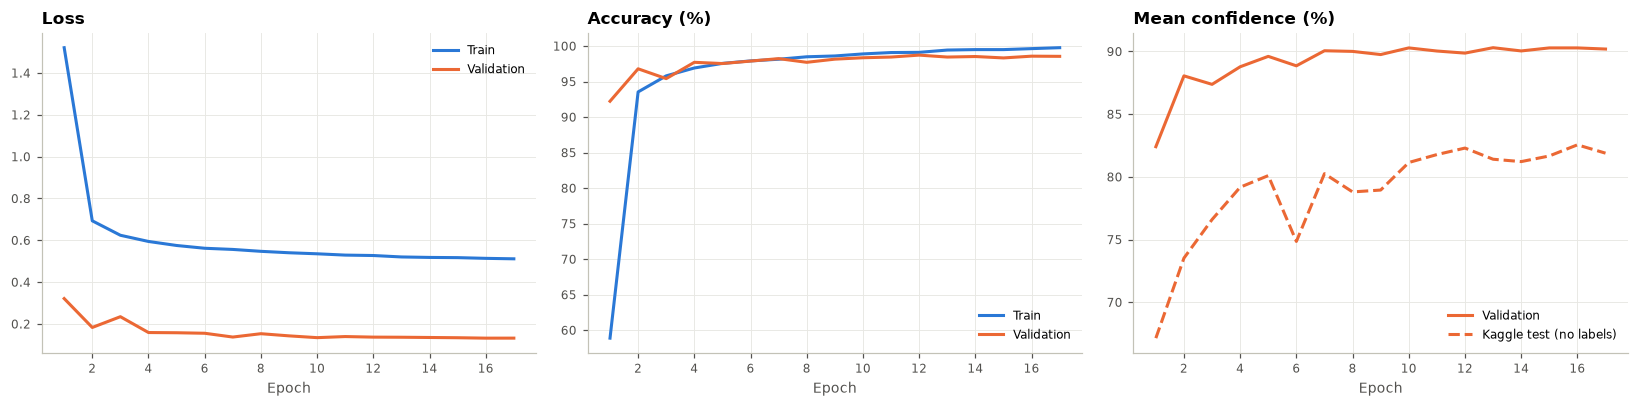

In [4]:
plot_training_curves(history)

## 4 · Internal test set

Measured once, on the best epoch: how well the model learned EuroSAT itself. It says nothing about
the Level-2A Kaggle images.

In [5]:
te_pred = predict_proba(model, data.te_images, normalizer).argmax(1)
val_acc = float(history["val_acc"].max())
test_acc = float((te_pred == data.y_te).mean())
print(f"Validation accuracy (best epoch): {val_acc:.2%}")
print(f"Internal test accuracy:           {test_acc:.2%}\n")
print(classification_report(data.y_te, te_pred, target_names=CLASSES, digits=3))

Validation accuracy (best epoch): 98.72%
Internal test accuracy:           98.57%

                      precision    recall  f1-score   support

          AnnualCrop      0.984     0.964     0.974       450
              Forest      0.996     0.998     0.997       450
HerbaceousVegetation      0.980     0.989     0.985       450
             Highway      0.992     0.960     0.976       375
          Industrial      0.987     0.995     0.991       375
             Pasture      0.970     0.970     0.970       300
       PermanentCrop      0.963     0.984     0.974       375
         Residential      0.998     0.996     0.997       450
               River      0.982     0.995     0.988       375
             SeaLake      0.998     1.000     0.999       450

            accuracy                          0.986      4050
           macro avg      0.985     0.985     0.985      4050
        weighted avg      0.986     0.986     0.986      4050



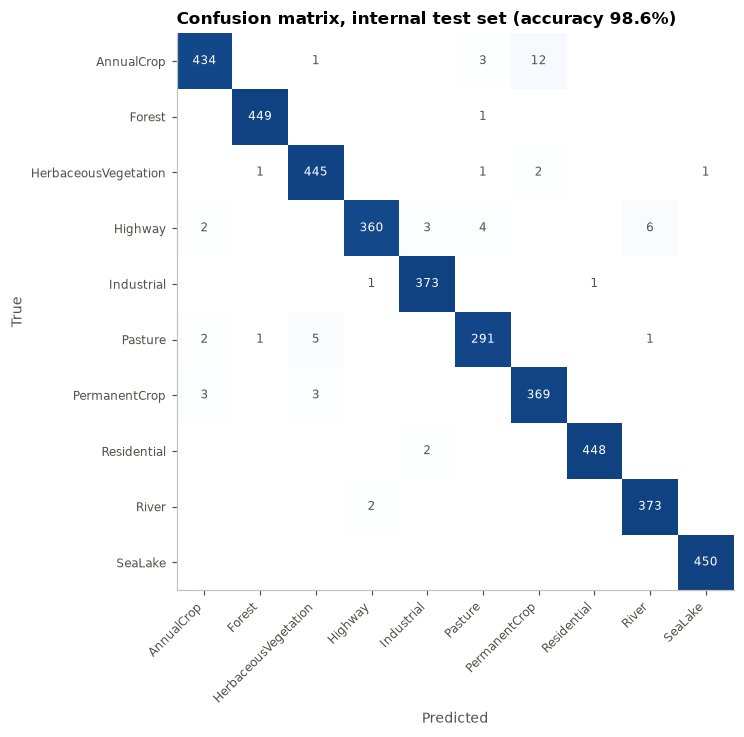

In [6]:
plot_confusion_matrix(data.y_te, te_pred, f"Confusion matrix, internal test set (accuracy {test_acc:.1%})")

## 5 · Kaggle predictions

Kaggle images as they are, normalised with the training statistics; test-time augmentation averages
the 8 rotations/flips of each image.

Mean confidence on Kaggle images: 79.5%


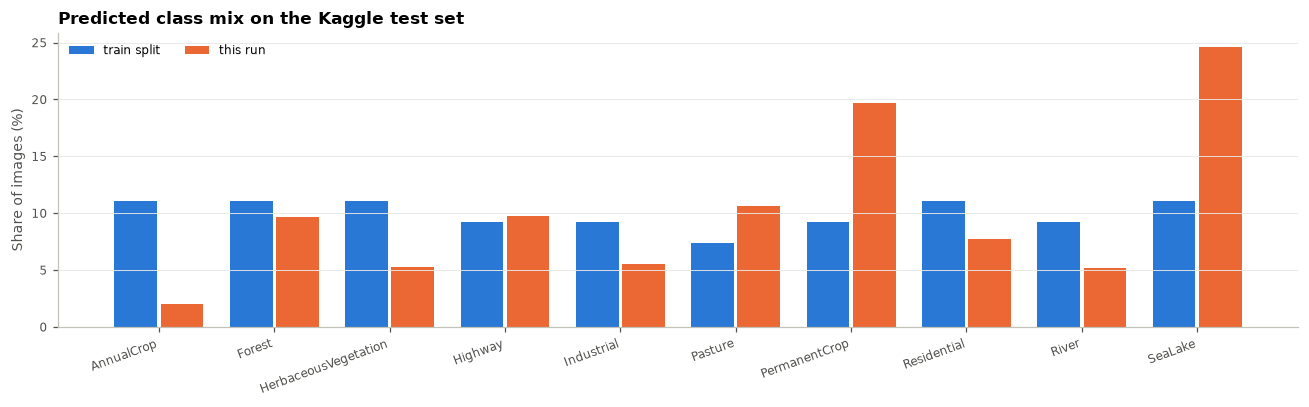

,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
train split,11.1,11.1,11.1,9.3,9.3,7.4,9.3,11.1,9.3,11.1
this run,2.0,9.7,5.2,9.7,5.5,10.6,19.7,7.8,5.2,24.6


In [7]:
kg_prob = predict_proba(model, data.kg_images, normalizer, tta=True)
kg_conf = float(kg_prob.max(1).mean())
mix = pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]), "this run": class_mix(kg_prob)})
print(f"Mean confidence on Kaggle images: {kg_conf:.1%}")
plot_class_mix(mix)
mix.round(1).T

## 6 · Save the run

With `LOAD_RUN` nothing is retrained or overwritten except `submission.csv`, recomputed from the saved weights.

In [8]:
if LOAD_RUN:
    run_dir = PROJECT_ROOT / LOAD_RUN
else:
    run_dir = new_run_dir(RUN_NAME)
    config = {
        "run_name": run_dir.name, "description": DESCRIPTION, "notebook": NOTEBOOK, "model": MODEL,
        "bands": BANDS, "seed": SEED, "n_params": n_params, "device": describe_device(device),
        "normalizer": asdict(normalizer), "corrections": CORRECTIONS, "train": asdict(cfg),
        "split": "split_seed42",
    }
    metrics = {
        "val_acc": val_acc, "internal_test_acc": test_acc,
        "best_epoch": int(history.loc[history["val_acc"].idxmax(), "epoch"]),
        "kaggle_mean_confidence": kg_conf,
        "kaggle_predicted_mix_pct": mix["this run"].round(2).to_dict(),
        "kaggle_public_score": None,  # fill in after submitting
    }
    save_run(run_dir, best_state, config, history, metrics)

write_submission(kg_prob, data.test_ids, run_dir / "submission.csv")
print("Run folder:", run_dir.relative_to(PROJECT_ROOT))
for f in sorted(run_dir.iterdir()):
    print(f"  {f.name:20} {f.stat().st_size / 1e6:6.2f} MB")

Run folder: runs/2026-10-12_1130_spectral_contrast_aug_hist_split_effb0
  config.json            0.00 MB
  history.csv            0.01 MB
  metrics.json           0.00 MB
  model.pt              16.35 MB
  submission.csv         0.06 MB


## 7 · With AdaBN (balanced)

As in `E03_adabn`: re-measure the BatchNorm statistics on Kaggle images, using all land images plus
enough water images to match the training water share. Saved as a second run folder. With `LOAD_RUN`,
the saved adapted weights are loaded instead of re-measuring.

In [9]:
if LOAD_RUN:
    ada_dir = find_run(f"adabn_balanced_{RUN_NAME}")
    ada_model, ada_norm, _ = load_run(ada_dir, device)
    print("Loaded adapted weights from", ada_dir.relative_to(PROJECT_ROOT))
else:
    ada_model, ada_norm, _ = load_run(run_dir, device)
    ada_model, bn_idx = adabn_balanced(ada_model, ada_norm, data, SEED)

views_plain = predict_views(model, data.kg_images, normalizer)
views_ada = predict_views(ada_model, data.kg_images, ada_norm)
prob_ada = views_ada.mean(0)

if not LOAD_RUN:
    ada_dir = new_run_dir(f"adabn_balanced_{RUN_NAME}")
    torch.save({k: v.detach().cpu() for k, v in ada_model.state_dict().items()}, ada_dir / "model.pt")
    ada_config = {**json.loads((run_dir / "config.json").read_text()), "run_name": ada_dir.name,
                  "description": DESCRIPTION + " + AdaBN balanced", "base_run": str(run_dir.relative_to(PROJECT_ROOT)),
                  "method": "adabn_balanced", "n_bn_images": int(len(bn_idx))}
    ada_metrics = {"kaggle_mean_confidence": float(prob_ada.max(1).mean()),
                   "kaggle_view_agreement": view_agreement(views_ada),
                   "kaggle_predicted_mix_pct": class_mix(prob_ada).round(2).to_dict(),
                   "kaggle_public_score": None}
    (ada_dir / "config.json").write_text(json.dumps(ada_config, indent=2))
    (ada_dir / "metrics.json").write_text(json.dumps(ada_metrics, indent=2))
write_submission(prob_ada, data.test_ids, ada_dir / "submission.csv")

sealake = CLASSES.index("SeaLake")
pd.DataFrame({
    "confidence (%)": [views_plain.mean(0).max(1).mean() * 100, prob_ada.max(1).mean() * 100],
    "view agreement (%)": [view_agreement(views_plain) * 100, view_agreement(views_ada) * 100],
    "SeaLake (%)": [(views_plain.mean(0).argmax(1) == sealake).mean() * 100, (prob_ada.argmax(1) == sealake).mean() * 100],
}, index=["this run", "this run + AdaBN balanced"]).round(1)

Loaded adapted weights from runs/2026-10-12_1131_adabn_balanced_spectral_contrast_aug_hist_split_effb0


,confidence (%),view agreement (%),SeaLake (%)
this run,79.500000,72.4,24.6
this run + AdaBN balanced,72.800003,70.9,24.6


## 8 · Conclusion

**Kaggle public score (with AdaBN): 67.85%**, −0.3 points vs the current best (`E04` contrast aug + AdaBN, 68.18%).

**Spectral matching removed almost the whole measured spectrum difference (gap 0.146 → 0.020), but did not raise the score.** The detail-profile difference is easy for a classifier to *detect*, yet the CNN apparently already ignores it for its decisions: it is a harmless difference, not the cause of the remaining errors.

The public leaderboard uses about half of the 4,232 test images, so differences below about 1 point
(roughly 20 images) are within noise. Summary of all three Fourier methods: `05_fourier_analysis` and the README.